# Supervised and unsupervised learning!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** performance of your model, as specified in each problem.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook (**problem.ipynb**) to Canvas. Deliver the notebook such that outputs are saved, ideally *restart* the kernel followed by *run all*.
- Use Kaggle to check your cluster assignments while you work. More details are in the problem description.
- Include your final **submission.csv** in the Canvas delivery, together with this notebook.

Good luck!

---


# 🎯 Problem 1: Training Neural Networks

### ❗️ The problem

Train neural networks for:
- A binary classification problem
- A non-linear regression problem

To reach the target performance, you may want to experiment with optimization techniques such as:
- Full-batch vs. mini-batch training
- Learning-rate scheduling (e.g., cosine annealing)
- Hyperparameter tuning (learning rate, batch size, depth, width)
- Optimizers (e.g., Adam, RMSprop, SGD)
- Activation functions (e.g., sigmoid, tanh, ReLU, GELU)
- Early stopping
- And more!

### 📋 Formal requirements

1. **Implementation**
   - Use Tensorflow/Keras or PyTorch for each problem (for Keras, you may find these guides useful: [Sequential model](https://keras.io/guides/sequential_model/) and [Training with built-in methods](https://keras.io/guides/training_with_built_in_methods/))
   - Try **at least three** of the techniques listed above.
   - Results must be **reproducible**: rerunning the notebook should yield the same metrics (fix random seeds).

2. **Performance**
   - **Classification**: at least **90% accuracy on the test set**.
   - **Regression**: at most **0.25 RMSE** on the test inputs, scored by `plot_complex_fit`.

3. **Discussion**
   - How did you ensure reproducibility?
   - Visualize/explain the network architecture for both classification and regression (e.g., block diagram, parameter counts, activation functions, etc.).
   - Plot the classification **decision boundary** with `plot_decision_boundary` from `utils`. Would the model generalize to larger feature values?
   - Plot train and held-out loss vs. epoch for classification and for regression. What do these curves tell you? Are the final values a good way to judge the model performance?
   - Which optimization techniques did you try? What worked and what did not?


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from utils import plot_complex_fit, plot_decision_boundary
# Importere til trening av nevrale nettverk
import keras
import tensorflow
from keras import layers
from keras import ops
keras.utils.set_random_seed(42) # Reproduserbare resultater

import os



# Any other imports you need

## Binary classification


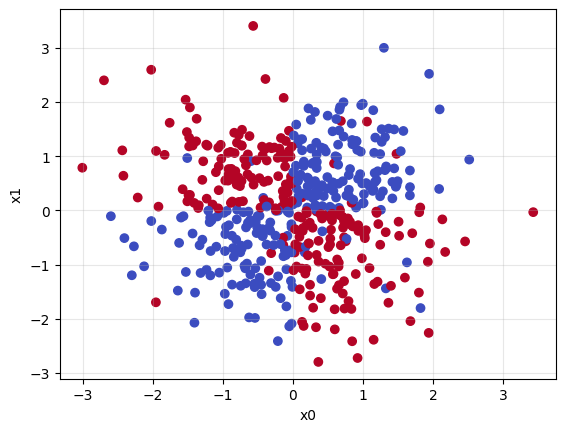

In [2]:
# This is our problem... It's basically XOR, but with continuous values (and a lot of noise!)
data = pd.read_csv("classification_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(test["x0"], test["x1"], c=test["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.grid(True, alpha=0.3)
plt.show()

Epoch 1/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6420 - loss: 0.6712 - val_accuracy: 0.6900 - val_loss: 0.6506
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7600 - loss: 0.6362 - val_accuracy: 0.7900 - val_loss: 0.6183
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8120 - loss: 0.6052 - val_accuracy: 0.8400 - val_loss: 0.5876
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8400 - loss: 0.5768 - val_accuracy: 0.8500 - val_loss: 0.5583
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8720 - loss: 0.5498 - val_accuracy: 0.8700 - val_loss: 0.5294
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8860 - loss: 0.5234 - val_accuracy: 0.8800 - val_loss: 0.5008
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9040 - loss: 0.4979 - val_accuracy: 0.9000 - val_loss: 0.4733
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9060 - loss: 0.4742 - val_accuracy: 0.9300 - 

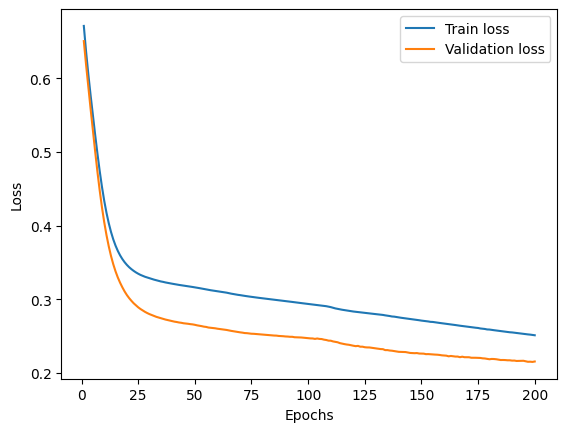

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 687us/step


(<Figure size 600x400 with 1 Axes>,
 <Axes: title={'center': 'Decision boundary'}, xlabel='x0', ylabel='x1'>)

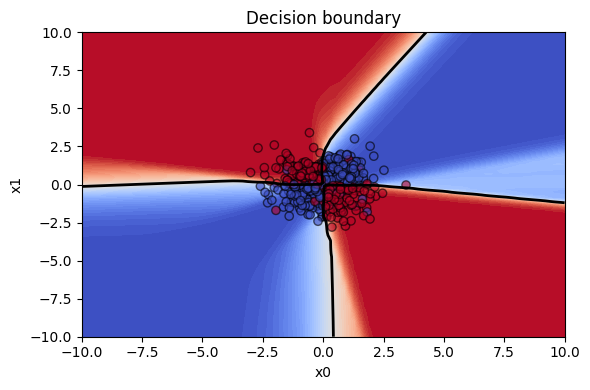

In [3]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
from sklearn.model_selection import train_test_split

X_train, x_test = train[["x0", "x1"]].values, test[["x0", "x1"]].values
y_train, y_test = train["y"].values, test["y"].values
epochs = 200


model = keras.Sequential(
    [   
        keras.Input(shape=(2,)),
        layers.Dense(80, activation="relu", name="layer1"),
        layers.Dense(80, activation="relu",  name="layer2"),
        layers.Dense(1, activation="sigmoid", name="output"),
    ]
)

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42) # Dele opp i trenings- og valideringsdata
model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1), loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=epochs, batch_size=50, validation_data=(X_val, y_val))
model.predict(x_test)
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'Test accuracy: {test_acc:.3f}')

# "Studere hvordan tapet utvikler seg på trenings- og valideringsdataene ved bruk av følgende kode"
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs_list = np.arange(1, len(train_losses) + 1)
plt.plot(epochs_list, train_losses, label="Train loss")
plt.plot(epochs_list, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot the decision boundary
plot_decision_boundary(predict=model.predict, xlim=(-10,10), ylim=(-10,10), threshold=0.5, points=x_test, labels=y_test)





### ❓ Visualize the network architecture for both classification and regression.


### ❓ Plot the classification decision boundary. Would the model generalize to larger feature values?

## Regression


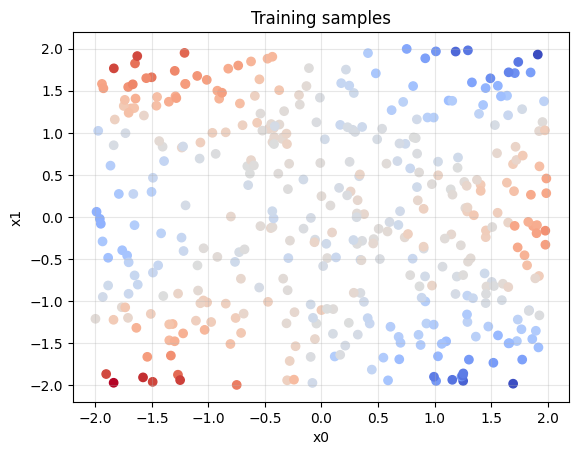

In [4]:
# We have a new dataset now. This time, the target is continuous.
# Test rows have no y. For a validation split, hold out part of train.
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(train["x0"], train["x1"], c=train["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Training samples")
plt.grid(True, alpha=0.3)
plt.show()

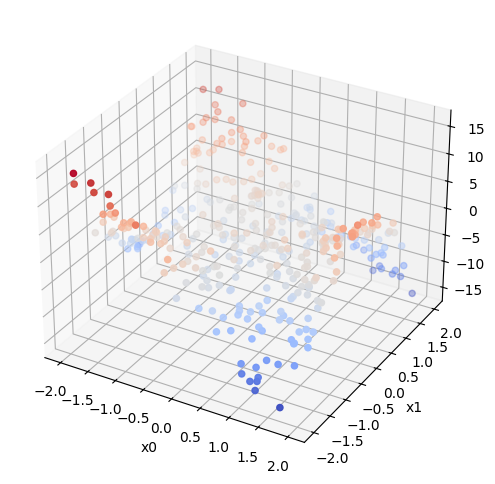

In [5]:
# Hmmm, maybe 3d is better
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train["x0"], train["x1"], train["y"], c=train["y"], cmap="coolwarm")
ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_zlabel("y")
plt.show()

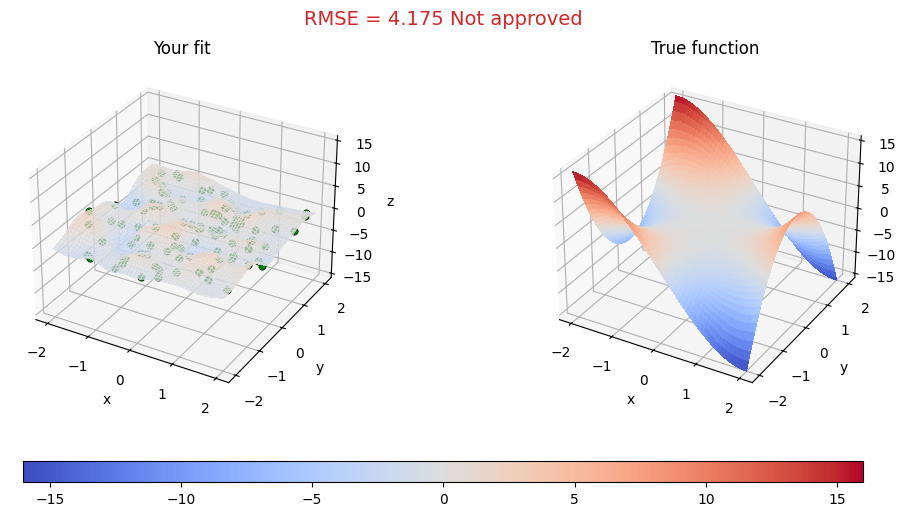

In [6]:
# plot_complex_fit compares your predictions to the true surface and prints RMSE
# plot_complex_fit has no noise, so expect a lower RMSE here
# The test rows have no y, so this is how you score them.
test_xy = test[["x0", "x1"]].values
y_pred_demo = np.random.randn(len(test))
plot_complex_fit(test_xy, y_pred_demo)
plt.show()

# Random predictions fail the 0.25 RMSE threshold.

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 22.0746 - mse: 22.0746 - val_loss: 18.9041 - val_mse: 18.9041
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 19.8974 - mse: 19.8974 - val_loss: 16.3239 - val_mse: 16.3239
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 16.8246 - mse: 16.8246 - val_loss: 12.5478 - val_mse: 12.5478
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 10.1270 - mse: 10.1270 - val_loss: 4.2893 - val_mse: 4.2893
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 4.0330 - mse: 4.0330 - val_loss: 3.0623 - val_mse: 3.0623
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2.9326 - mse: 2.9326 - val_loss: 2.3715 - val_mse: 2.3715
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 3.0188 - mse: 3.0188 - val_loss: 1.7033 - val_mse: 1.7033
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2.7731 - mse: 2.7731 - val_loss: 1.6050 - val_mse: 1.6050
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 

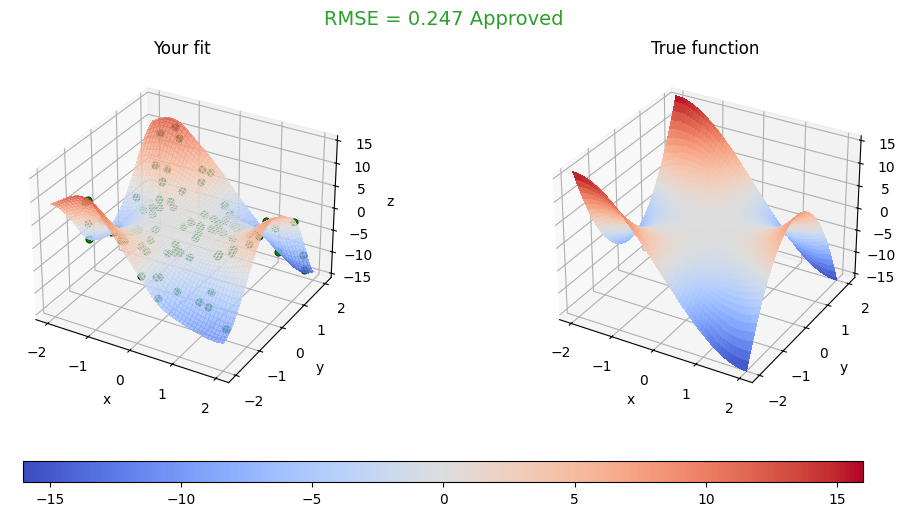

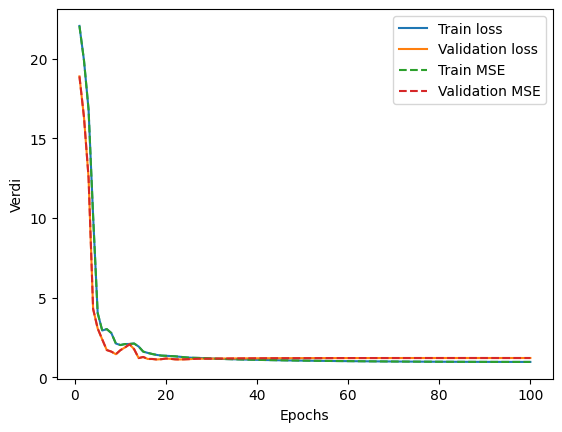

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from utils import plot_complex_fit, plot_decision_boundary
# Importere til trening av nevrale nettverk
import keras
import tensorflow
from keras import layers
from keras import ops
keras.utils.set_random_seed(42) # Reproduserbare resultater

from sklearn.model_selection import train_test_split


# ====================================
# YOUR CODE GOES HERE
# ====================================
epochs = 100
lr =  0.01
batch_size = 40


model_reg = keras.Sequential(
    [   
        keras.Input(shape=(2,)),
        layers.Dense(64, activation="gelu", name="layer1"),
        layers.Dense(64, activation="gelu", name="layer2"),
        layers.Dense(64, activation="gelu", name="layer3"),
        layers.Dense(1, name="output"),
    ]
)

X_tr, X_val, y_tr, y_val = train_test_split(train[["x0", "x1"]].values, train["y"].values, test_size=0.2, random_state=42) # Dele opp i trenings- og valideringsdata

# Bruk av CosineDelay, endre learning rate underveis

steps_per_epoch = int(np.ceil(len(X_tr) / batch_size))

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=lr,                 # startverdi, f.eks. 0.01
    decay_steps=epochs * steps_per_epoch,     # antall steg før lr når bunnen
    alpha=0.0,                                # sluttverdi som andel av start (0.0 = helt ned til 0)
)

model_reg.compile(optimizer=keras.optimizers.Adam(learning_rate=lr_schedule), loss="mse", metrics=["mse"])
history_reg = model_reg.fit(X_tr, y_tr, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val))
y_pred = model_reg.predict(test_xy, verbose=0) # "verbose bestemmer hvor mye Keras skriver ut mens den jobber"
plot_complex_fit(test_xy, y_pred)
plt.show()

# Plotting
epochs_list = np.arange(1, len(history_reg.history["loss"]) + 1)
plt.plot(epochs_list, history_reg.history["loss"], label="Train loss")
plt.plot(epochs_list, history_reg.history["val_loss"], label="Validation loss")
plt.plot(epochs_list, history_reg.history["mse"], "--", label="Train MSE")
plt.plot(epochs_list, history_reg.history["val_mse"], "--", label="Validation MSE")
plt.xlabel("Epochs")
plt.ylabel("Verdi")
plt.legend()
plt.show()



### ❓ Plot train and held-out loss vs. epoch. What do these curves tell you? Are the final values a good way to judge the model?


### ❓ Which optimization techniques did you try? What worked and what did not?


### ❓ How did you ensure reproducibility?

In [8]:
# VISUALIZE THE NETWORK ARCHITECTURE
# For classification we can use the following:
model.summary()
model_reg.summary()

# PLOT THE CLASSIFICATION DECISION BOUNDARY. WOULD THE MODEL GENERALIZE TO LARGER FEATURE VALUES?
# Yes, the model generalize to larger feature values

# PLOT TRAIN AND HELD-OUT LOSS VS EPOCH. WHAT DO THESE CURVES TELL YOU? ARE THE FINAL VALUES A GOOD WAY TO JUDGE THE MODEL?
# Valideringsdataene begynner ikke å stige mer enn treningsdataene, og de er parallelle hele veien. Det er en god ting.
# Men vi trenger fortsatt å se hvordan modellen gjør det på testdataene for å avgjøre om det er en god modell. Vi fikk 0,91 accuracy på testdataene.

# WHICH OPTIMIZATION TECHNIQUES DID YOU TRY? WHAT WORKED AND WHAT DID NOT?
# I changed the depth on the neural network, but always kept the width the same. As expected the higher depth, the better accuracy.
# Jeg brukte stort sett tuning av hyperparametere som læringsrate, epochs og batch_size. Hvis jeg økte batch_sizen gjorde modellen det dårligere.
# For regresjon var det også justering av hyperparametere jeg brukte, her learning rate, men også hvilken optimizer jeg brukte. Når jeg brukte Adam, bedret 
# resultatene seg. Jeg fikk fortsatt ikke det nødvendige resultatet på under 0,25 før jeg brukte CosineDelay. 

# HOW DID YOU ENSURE REPRODUCIBILITY?
# I used set_random_seed(42).



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 80)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 80)             │         6,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            81 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,803 (26.58 KB)

 Trainable params: 6,801 (26.57 KB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer3 (Dense)                  │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,732 (100.52 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 17,155 (67.02 KB)

# 🤖 Problem 2: Unsupervised Learning

### ❗️ The problem

1. Identify the number of clusters in the dataset.
2. Assign a cluster label to every row and validate on [Kaggle](https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86) until you reach at least **99%** clustering accuracy.
3. Visualize the clusters in 2D, and identify what each cluster is.
4. Some rows do not belong with the others. Find those rows and show what they are.

### 💡 Hints

1. **Large Dataset**: The data set **unsupervised_data.csv** is huge! There are many features, dimensionality reduction can help.
2. **Unsupervised Learning**: No target labels are provided, patterns must come from the features alone.
3. **Data Obfuscation**: The data has a structured format. Try to find the meaning and correct ordering of the features.

### 📚 Resources

- [Clustering in scikit-learn](https://scikit-learn.org/stable/modules/clustering.html) (KMeans, DBSCAN, …)
- [Manifold learning](https://scikit-learn.org/stable/modules/manifold.html) (PCA, t-SNE, …)
- Feel free to use any other methods you find in the scikit-learn documentation!
- Kaggle competition (50 submissions per day)

### 📋 Formal requirements

1. Identify the number of clusters in the dataset.
2. Reach at least **99%** clustering accuracy on Kaggle.
3. Visualize the clusters in 2D.
4. Identify what each cluster corresponds to.
5. Some rows do not belong here, perform anomaly detection and find those samples.
6. **Discussion**
   - Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.
   - Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.
   - What is the hidden modality? How does this impact dimensionality reduction and clustering?
   - List the facilities in Trondheim and how you identified them.
   - How did you detect the rows that do not belong, and what were they?

## 🏆 Kaggle

Kaggle is a popular platform for machine learning competitions. It allows hosts to share datasets while keeping the labels hidden from the participants. The clustering labels are not available locally. Use **Kaggle** to check your cluster assignments.

- Invitation: https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86
- Upload a CSV with columns `ID` and `cluster` (integer cluster ids) to check your score.
- Also include the final **submission.csv** in your Canvas delivery, together with the notebook.


In [9]:
# Why did we skip the first row? Maybe it's useful metadata for later...
data = pd.read_csv("unsupervised_data.csv", skiprows=1, header=None)
data = data.reset_index(names="ID")
data

C:\Users\Tørres L\AppData\Local\Temp\ipykernel_22560\3436741196.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data = data.reset_index(names="ID")


,ID,0,1,2,3,4,5,6,7,8,...,16374,16375,16376,16377,16378,16379,16380,16381,16382,16383
0,0,0.314365,0.646305,0.323849,0.238492,0.655790,0.646305,0.646305,0.409205,0.646305,...,0.646305,0.646305,0.655790,0.238492,0.646305,0.674758,0.646305,0.238492,0.655790,0.646305
1,1,0.587628,0.494976,0.559832,-0.246237,0.513506,0.550567,0.522772,0.596893,0.606158,...,0.587628,0.550567,0.587628,0.587628,0.550567,0.587628,0.550567,0.596893,0.494976,0.587628
2,2,0.590203,0.367673,0.367673,0.367673,0.367673,0.590203,0.367673,0.590203,0.590203,...,0.590203,0.367673,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.476556
3,3,0.589296,0.589296,0.579825,0.551415,0.579825,0.579825,0.608236,0.579825,0.646118,...,0.532474,0.523003,0.589296,0.589296,0.551415,0.134721,0.475652,0.589296,0.570355,0.551415
4,4,0.660095,0.470676,0.190366,0.672806,0.470761,0.672766,0.672652,0.666151,0.672987,...,0.432001,0.672222,0.190568,0.217329,0.633684,0.673294,0.587914,0.671023,0.207578,0.470765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3995,0.340739,0.340739,0.340739,0.681823,0.340739,0.340739,0.340739,0.672083,0.340739,...,0.340739,0.662355,0.340739,0.759779,0.331011,0.759779,0.340739,0.691563,0.340734,0.720789
3996,3996,0.384257,0.384257,0.675221,0.384257,0.384257,0.675221,0.384257,0.675221,0.675221,...,0.675221,0.384257,0.675221,0.675221,0.675221,0.384257,0.384257,0.384257,0.675221,0.675221
3997,3997,0.641837,0.651135,0.251329,0.251329,0.651135,0.651135,0.251329,0.651135,0.651135,...,0.251329,0.251329,0.651135,0.251329,0.409392,0.604646,0.651135,0.651135,0.660433,0.251329
3998,3998,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,-0.212897,0.555533,...,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533


In [10]:
# Probably too many columns for naive clustering on raw pixels
data.info(max_cols=5)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Columns: 16385 entries, ID to 16383
dtypes: float64(16384), int64(1)
memory usage: 500.0 MB


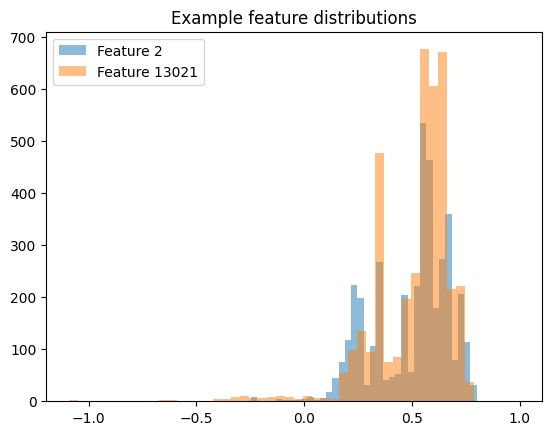

In [11]:
features = data.drop(columns="ID")
plt.hist(features.iloc[:, 2], bins=50, alpha=0.5, label="Feature 2")
plt.hist(features.iloc[:, 13021], bins=50, alpha=0.5, label="Feature 13021")
plt.legend()
plt.title("Example feature distributions")
plt.show()

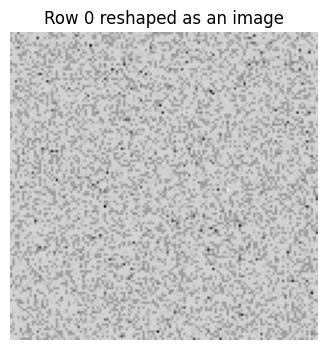

16383
[9858, 2932, 12843, 5156, 2677, 9520, 291, 14843, 10287, 196, 13099, 8765, 9176, 4391, 4469, 8165, 7914, 14291, 6266, 15581, 13311, 13639, 7515, 795, 5805, 5770, 6334, 9522, 4561, 12395, 6848, 15926, 4455, 3387, 12093, 8309, 13084, 12271, 2684, 4564, 9960, 14156, 5711, 12603, 13431, 4105, 8498, 16113, 1683, 5391, 15520, 11545, 14854, 13049, 387, 1039, 2714, 11097, 11317, 14933, 9618, 3441, 10840, 9955, 7047, 88, 13564, 4874, 10581, 8158, 3, 5227, 11784, 14425, 13930, 6127, 12825, 2919, 6178, 13017, 8284, 5927, 5553, 11491, 4057, 102, 8287, 149, 1650, 254, 7581, 4417, 12272, 7681, 290, 8793, 2183, 2861, 8545, 4554, 13453, 5692, 7514, 2177, 6526, 8776, 9740, 4622, 7356, 3909, 13893, 7034, 123, 3283, 1034, 11896, 13294, 4129, 9313, 3859, 304, 3269, 5277, 6137, 6685, 9100, 5483, 6494, 5683, 14937, 7652, 2676, 2993, 9674, 4984, 2673, 8863, 7856, 14470, 15220, 16118, 10835, 9933, 14728, 2435, 3819, 4220, 8126, 14429, 5265, 2455, 3288, 14994, 12063, 10920, 8201, 11225, 15465, 7049, 1212

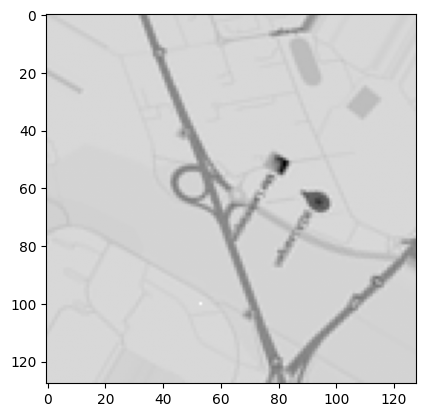

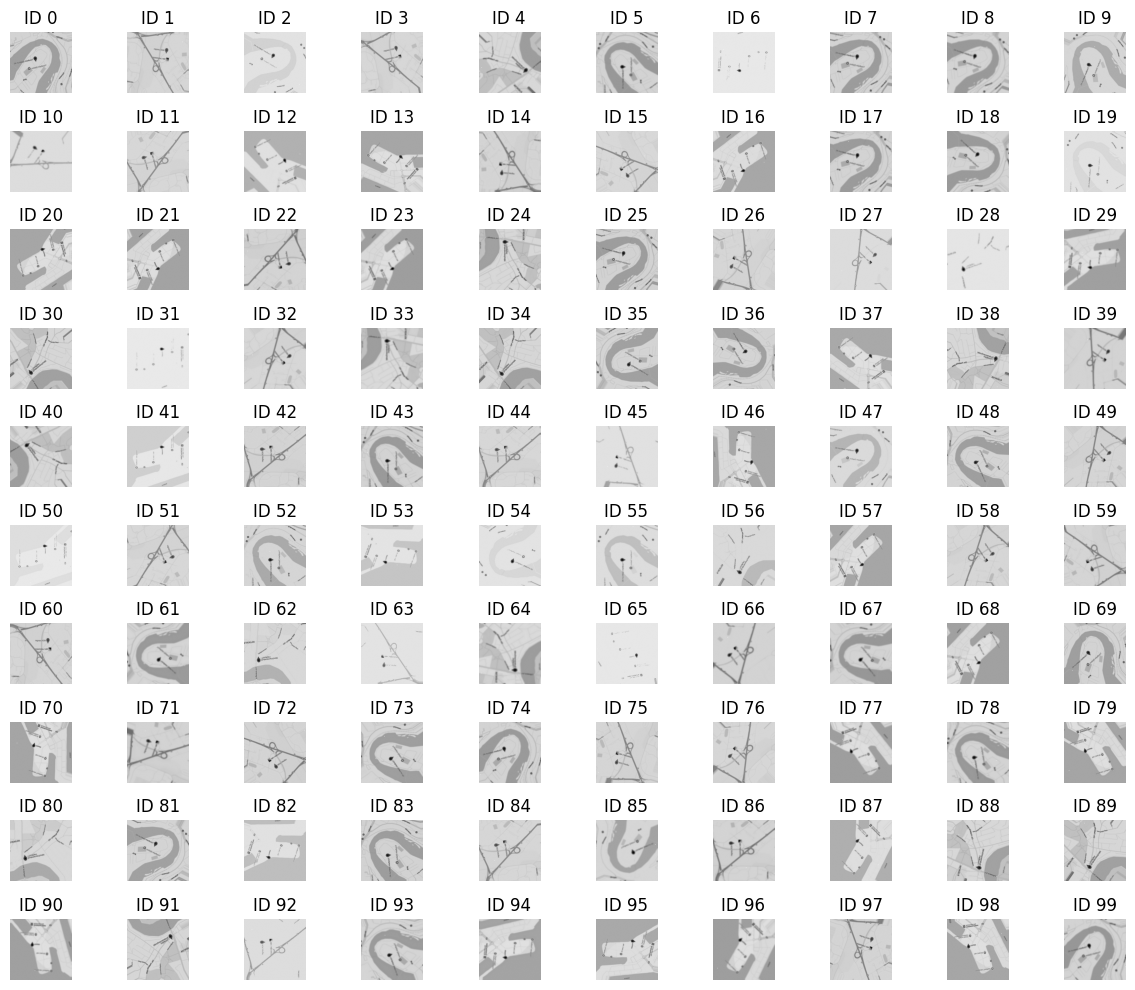

In [51]:
# 16384 = 128 × 128. Coincidence? This may be a flattened grayscale image...
row = data.iloc[0, 1:].astype(float).to_numpy()
image = row.reshape(128, 128).T
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Row 0 reshaped as an image")
plt.axis("off")
plt.show()

# If it really is an image, then pixels look scrambled.
# The true order may be encoded elsewhere. Maybe the dropped row contained important information?

# Sjekker ut første rad som ble gjemt tidligere
first_row = pd.read_csv("unsupervised_data.csv", nrows=0).columns

splitted = []
for i in first_row:
    splitted.append(i.split("_"))

numbers = []
for i in splitted:
    numbers.append(int(i[1]))

print(max(numbers))
print(numbers)
sortert = np.argsort(numbers)

MA = features.to_numpy()[:, sortert]
row_sortert = MA[15]
image_sortert = row_sortert.reshape(128,128)
plt.imshow(image_sortert, cmap="gray")


navn = np.array([2, 0, 3, 1])     # "col_2, col_0, col_3, col_1"
rekkefolge = np.argsort(navn)
print(rekkefolge)

M = np.array([[20, 0, 30, 10],
              [21, 1, 31, 11]])
print(M[:, rekkefolge])

# Plott for 20 ulike bilder (AI-kode):

fig, axes = plt.subplots(10, 10, figsize=(12, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(MA[i].reshape(128, 128).T, cmap="gray")
    ax.set_title(f"ID {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# KOMMENTAR HER ETTER Å PRINTET EN DEL AV BILDENE:
# Det er åpenbart utsnitt av noen steder i Trondheim hvor vinkelen på bildene er ulik.
# Jeg ser for meg at de ulike bildene skal tilhøre de samme klyngene, og at innad i samme klynge avviker bilder som har ulik vinkel.
# Det må vel da være for eksempel slyngene i t-SNE som er disse ulike vinklene på bildene.



In [13]:
# Kaggle submission format. The cluster ids here are just placeholders and do not hint at k.
sample_submission = pd.read_csv("sample_submission.csv")
sample_submission.head()

,ID,cluster
0,0,2
1,1,6
2,2,3
3,3,3
4,4,8


[[  0.75806824   0.67145069]
 [ -1.55539929  -0.20012269]
 [ -1.08037043  -0.79836667]
 ...
 [  0.85385964   1.48402769]
 [  2.82400718  -1.91394122]
 [  1.15719232 -13.17313879]]


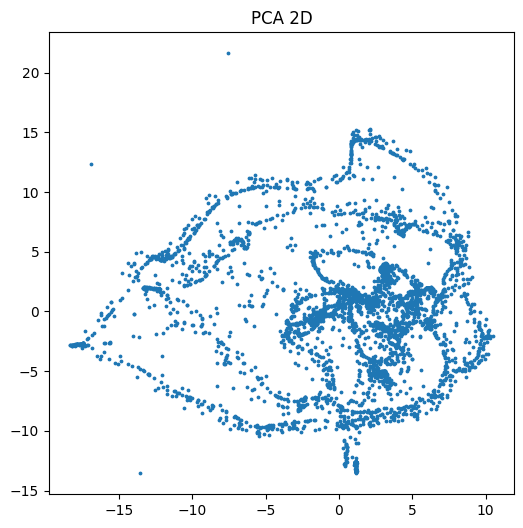

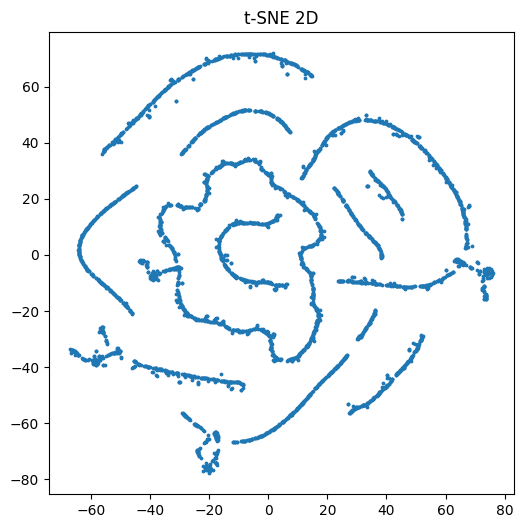

,ID,cluster
0,0,4
1,1,3
2,2,4
3,3,3
4,4,0


In [52]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
# Plotting av dataene, både PCA og TSNE
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

k = 6

X_pca = PCA(n_components=50, random_state=0).fit_transform(features)


X_2d_pca = PCA(n_components=2, random_state=0).fit_transform(features)
print(X_2d_pca)


plt.figure(figsize=(6, 6))
plt.scatter(X_2d_pca[:, 0], X_2d_pca[:, 1], s=3)
plt.title("PCA 2D")
plt.show()

X_2d_tsne = TSNE(n_components=2, random_state=0).fit_transform(features)

plt.figure(figsize=(6, 6))
plt.scatter(X_2d_tsne[:, 0], X_2d_tsne[:, 1], s=3)
plt.title("t-SNE 2D")
plt.show()


labels_kmeans = KMeans(n_clusters=k, random_state=0, n_init=10).fit_predict(X_pca)
db_scan = DBSCAN(eps = 0.5, min_samples=50)

#Kommentar etter plott:
# Det virker som at t-SNE har tydeligere definerte klynger. PCA har noen outliers den greier å definere i større grad
# Med tsne har jeg bare telt over røflig og kommet frem til 16 klynger...?? er det da det jeg skal velge som k?? På k-means da eventuelt?

sub = pd.DataFrame({"ID": sample_submission["ID"], "cluster": labels_kmeans})
sub.to_csv("submission.csv", index=False)
sub.head()






### ❓ Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.


### ❓ Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.


### ❓ What is the hidden modality? How does this impact dimensionality reduction and clustering?


### ❓ List the facilities in Trondheim and how you identified them.

### ❓ How did you detect the rows that do not belong, and what were they?


In [ ]:
# WHICH DIMENSIONALITY REDUCTION METHODS HELPED YOU CHOOSE *K*? COMPARE PCA AND T-SNE IN 2D.
# I used both PCA and t-SNE from the original datapoints and plotted. By the plot, it looked to me that t-SNE clustered the data better.

# WHICH CLUSTERING ALGORITHM AND HYPERPARAMETERS DID YOU USE? COMPARE KMEANS AND DBSCAN.

# WHAT IS THE HIDDEN MODALITY? HOW DOES THIS IMPACT DIMENSIONALITY REDUCTION AND CLUSTERING?
# The hidden modality is that the pictures are presented in differnet angles.

# LIST THE FACILITIES IN TRONDHEIM AND HOW YOU IDENTIFIED THEM.

#  HOW DID YOU DETECT THE ROWS THAT DO NOT BELONG, AND WHAT WERE THEY?






---

## Note: Clustering accuracy metric

Kaggle scores clustering with **label-invariant** accuracy: only the grouping matters, not the numeric ids.

If true labels are `[0, 0, 0, 1, 1, 1]` and you predict `[1, 1, 1, 0, 0, 0]`, accuracy is **1.0** because clusters match after renaming.

### How it is computed

1. Build a contingency matrix between true and predicted labels.
2. Find the best label matching (Hungarian algorithm / `linear_sum_assignment`).
3. Accuracy = matched points / total points.

---

In [15]:
import scipy.optimize
import sklearn.metrics


def calculate_clustering_accuracy(true_labels: np.ndarray, cluster_labels: np.ndarray) -> float:
    """Clustering accuracy with optimal permutation of cluster ids."""
    if true_labels.size != cluster_labels.size:
        raise ValueError("true_labels and cluster_labels must have the same length.")

    contingency = sklearn.metrics.cluster.contingency_matrix(true_labels, cluster_labels)
    row_ind, col_ind = scipy.optimize.linear_sum_assignment(-contingency)
    correct = contingency[row_ind, col_ind].sum()
    return correct / true_labels.size

In [16]:
true_labels = np.array([0, 1, 2, 0, 1, 2])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(1.0)

In [17]:
# Single cluster in ground truth: accuracy is share of majority predicted cluster
true_labels = np.array([0, 0, 0, 0, 0, 0])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.3333333333333333)

In [18]:
# Wrong number of groups: low accuracy
true_labels = np.array([1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.5)